<a href="https://colab.research.google.com/github/feliciadominic14-create/Homework/blob/main/Felicia_TelcoChurn_KNN_LogReg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filepath='/content/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(filepath)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [5]:
df=df.drop(columns=["customerID"],errors='ignore')

In [6]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.shape

(7043, 20)

In [8]:
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [9]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [10]:
df.nunique()

,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3


In [11]:
df.duplicated().sum()

np.int64(22)

In [13]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [14]:
df["Churn"].value_counts(normalize=True).round(4)

,proportion
Churn,
No,0.7346
Yes,0.2654


In [18]:
bla = df["TotalCharges"].astype(str).str.strip() == ""

In [19]:
bla.sum()

np.int64(11)

In [22]:
print(df.loc[bla, [ "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

      tenure  MonthlyCharges TotalCharges  Contract Churn
488        0           52.55               Two year    No
753        0           20.25               Two year    No
936        0           80.85               Two year    No
1082       0           25.75               Two year    No
1340       0           56.05               Two year    No
3331       0           19.85               Two year    No
3826       0           25.35               Two year    No
4380       0           20.00               Two year    No
5218       0           19.70               One year    No
6670       0           73.35               Two year    No
6754       0           61.90               Two year    No


/tmp/ipykernel_2874/1995369653.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette=["#2b8cbe", "#e34a33"])


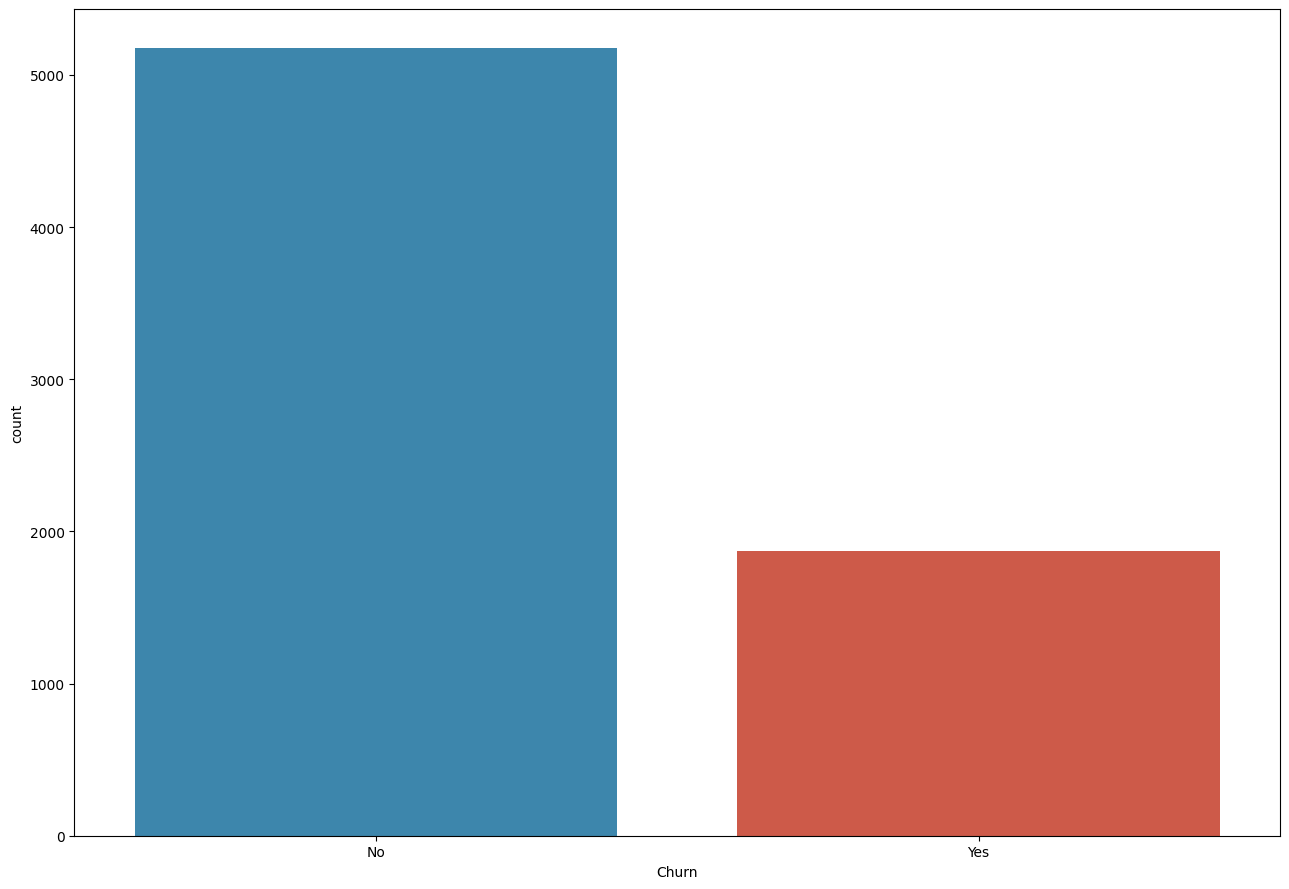

In [34]:
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")

fig= plt.subplots(figsize=(13, 9))
sns.countplot(data=df, x="Churn", palette=["#2b8cbe", "#e34a33"])

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

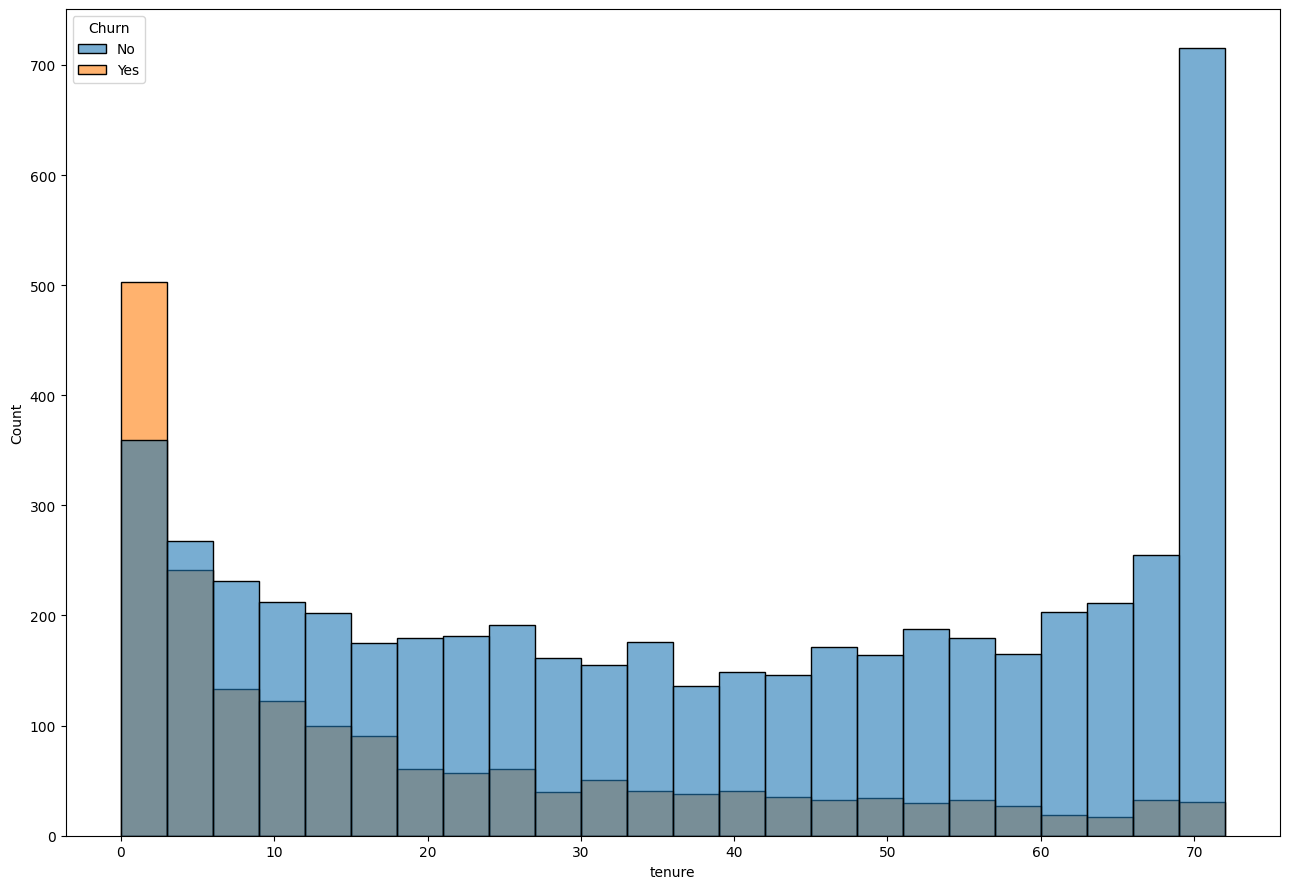

In [37]:
fig= plt.subplots(figsize=(13, 9))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, multiple="layer", alpha=0.6)

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

/tmp/ipykernel_2874/2114131648.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#2b8cbe", "#e34a33"])


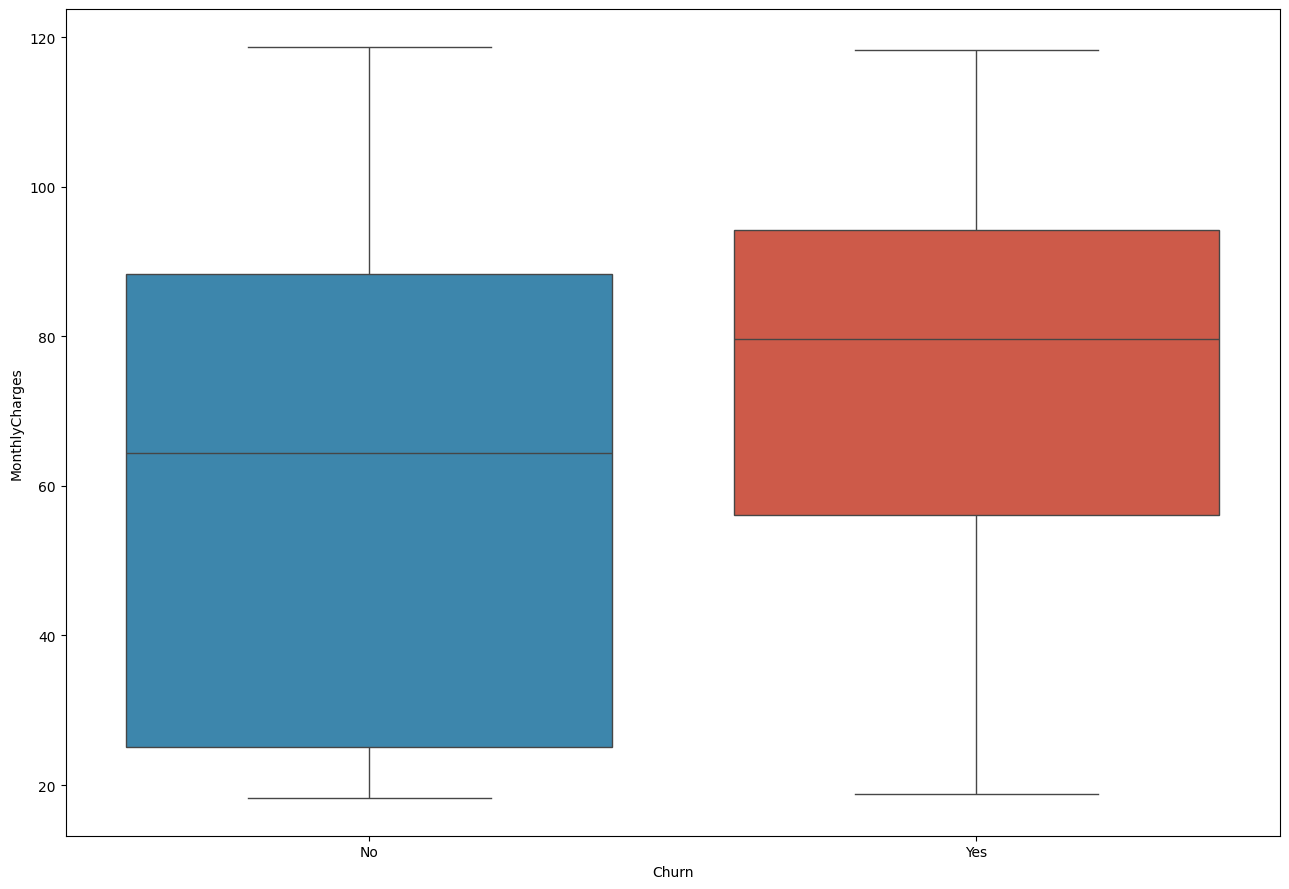

In [40]:
fig= plt.subplots(figsize=(13, 9))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#2b8cbe", "#e34a33"])
plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

/tmp/ipykernel_2874/3498447280.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_rate_contract, x="Contract", y="ChurnRate", palette="viridis")


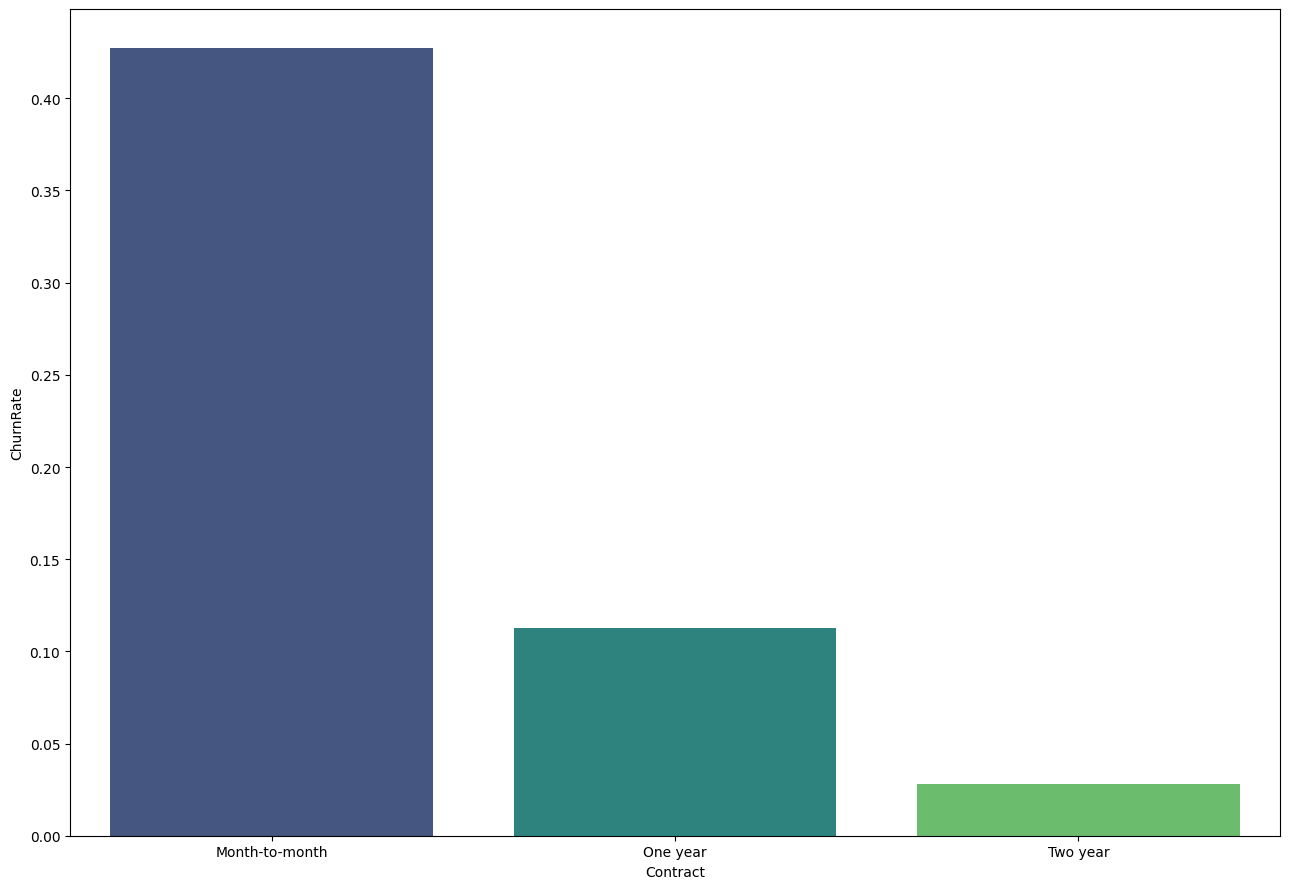

In [41]:
fig= plt.subplots(figsize=(13, 9))
churn_rate_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).reset_index(name="ChurnRate")
sns.barplot(data=churn_rate_contract, x="Contract", y="ChurnRate", palette="viridis")
plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

In [43]:
from sklearn.model_selection import train_test_split

work_df = df.drop(columns=["TotalCharges"]).copy()
work_df["target"] = (work_df["Churn"] == "Yes").astype(int)
work_df = work_df.drop(columns=["Churn"])

train_df, temp_df = train_test_split(work_df, test_size=0.40, random_state=42, stratify=work_df["target"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["target"])
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 4225, Val: 1409, Test: 1409


In [44]:
n_dup_train = train_df.duplicated().sum()
train_df = train_df.drop_duplicates().copy()
print(f"Dropped {n_dup_train} duplicate rows from train_df; train rows now: {len(train_df)}")

tc_median_train = train_df["TotalCharges_num"].median()
print(f"TotalCharges_num median (train only): {tc_median_train:.2f}")

for split in [train_df, val_df, test_df]:
    split["TotalCharges_num"] = split["TotalCharges_num"].fillna(tc_median_train)

Dropped 7 duplicate rows from train_df; train rows now: 4218
TotalCharges_num median (train only): 1376.50


In [45]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges_num"]
for col in num_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    for split in [train_df, val_df, test_df]:
        split[col] = split[col].clip(lower=lower, upper=upper)

In [46]:
for split in [train_df, val_df, test_df]:
    split["gender"] = (split["gender"] == "Male").astype(int)
    for bcol in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        split[bcol] = (split[bcol] == "Yes").astype(int)

In [47]:
cat_multi_cols = [
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaymentMethod"
]

In [48]:
X_train_full = pd.get_dummies(train_df.drop(columns=["target"]), columns=cat_multi_cols, drop_first=True, dtype=int)
y_train = train_df["target"].copy()

In [49]:
X_val_full = pd.get_dummies(val_df.drop(columns=["target"]), columns=cat_multi_cols, drop_first=True, dtype=int).reindex(columns=X_train_full.columns, fill_value=0)
y_val = val_df["target"].copy()

In [50]:
X_test_full = pd.get_dummies(test_df.drop(columns=["target"]), columns=cat_multi_cols, drop_first=True, dtype=int).reindex(columns=X_train_full.columns, fill_value=0)
y_test = test_df["target"].copy()

In [51]:
train_corr_df = X_train_full.copy()
train_corr_df["target"] = y_train
corr_with_target = train_corr_df.corr()["target"].drop("target")

In [52]:
selected_features = corr_with_target[corr_with_target.abs() >= 0.03].index.tolist()
dropped_features = [c for c in X_train_full.columns if c not in selected_features]
print(f"Selected {len(selected_features)} features; dropped {len(dropped_features)}: {dropped_features}")

Selected 27 features; dropped 3: ['gender', 'PhoneService', 'MultipleLines_No phone service']


In [53]:
X_train_sel = X_train_full[selected_features].copy()
X_val_sel = X_val_full[selected_features].copy()
X_test_sel = X_test_full[selected_features].copy()

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

In [55]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_sel), columns=selected_features, index=X_train_sel.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val_sel), columns=selected_features, index=X_val_sel.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_sel), columns=selected_features, index=X_test_sel.index)

In [60]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)
X_val_scaled = scaler.transform(X_val_sel)
X_test_scaled = scaler.transform(X_test_sel)

def smote_train(X, y, k=5, seed=42):
  rng = np.random.default_rng(seed)
  X_maj, X_min = X[y == 0], X[y == 1]
  n_to_add = len(X_maj) - len(X_min)
  if n_to_add <= 0:
    return X, y

  nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_min))).fit(X_min)
  neighbors = nn.kneighbors(return_distance=False)[:, 1:]

  idx = rng.integers(0, len(X_min), size=n_to_add)
  nbr_idx = neighbors[idx, rng.integers(0, neighbors.shape[1], size=n_to_add)]
  gap = rng.random((n_to_add, 1))
  X_synth = X_min[idx] + gap * (X_min[nbr_idx] - X_min[idx])

  X_bal = np.vstack([X, X_synth])
  y_bal = np.concatenate([y, np.ones(n_to_add, dtype=y.dtype)])
  order = rng.permutation(len(y_bal))
  return X_bal[order], y_bal[order]

y_train_arr = y_train.to_numpy() if hasattr(y_train, "to_numpy") else np.asarray(y_train)
X_train_smote, y_train_smote = smote_train(X_train_scaled, y_train_arr)

print(
    "Training counts after SMOTE:",
    pd.Series(y_train_smote).value_counts().to_dict(),
)

Training counts after SMOTE: {1: 3101, 0: 3101}


In [61]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

In [65]:
k_candidates = list(range(1, 32, 2))
val_f1_scores = []

for k in k_candidates:
  knn_tmp = KNeighborsClassifier(n_neighbors=k)
  knn_tmp.fit(X_train_smote, y_train_smote)
  val_pred = knn_tmp.predict(X_val_scaled)  # X_val_scaled is already a NumPy array
  val_f1_scores.append(f1_score(y_val, val_pred))

In [66]:
best_idx = int(np.argmax(val_f1_scores))
best_k = k_candidates[best_idx]
best_val_f1 = val_f1_scores[best_idx]
print(f"Best k on validation set: k={best_k} (Validation F1 = {best_val_f1:.4f})")

Best k on validation set: k=17 (Validation F1 = 0.6038)


In [67]:
plt.figure(figsize=(8, 4.5))
plt.plot(k_candidates, val_f1_scores, marker="o", color="#2b8cbe")
plt.axvline(best_k, color="#e34a33", linestyle="--", label=f"Best k={best_k} (F1={best_val_f1:.4f})")
plt.title("KNN Validation F1-Score Across k Values")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation F1-Score (Churn=1)")
plt.xticks(k_candidates)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_val_k.png", dpi=150)
plt.close()

In [68]:
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_smote, y_train_smote)


KNeighborsClassifier(n_neighbors=17)

In [69]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_smote, y_train_smote)

LogisticRegression(max_iter=1000, random_state=42)

In [70]:
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, classification_report
)

In [72]:
y_test_pred_knn = knn_final.predict(X_test_scaled)
y_test_pred_lr = log_reg.predict(X_test_scaled)
y_test_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

In [73]:
for name, preds in [(f"KNN (k={best_k})", y_test_pred_knn), ("Logistic Regression (t=0.50)", y_test_pred_lr)]:
    print(f"=== {name} ===")
    print(f"Accuracy : {accuracy_score(y_test, preds):.4f}")
    print(f"Precision: {precision_score(y_test, preds):.4f}")
    print(f"Recall   : {recall_score(y_test, preds):.4f}")
    print(f"F1-Score : {f1_score(y_test, preds):.4f}")
    print(classification_report(y_test, preds, target_names=["No Churn (0)", "Churn (1)"]))

=== KNN (k=17) ===
Accuracy : 0.6849
Precision: 0.4478
Recall   : 0.8021
F1-Score : 0.5747
              precision    recall  f1-score   support

No Churn (0)       0.90      0.64      0.75      1035
   Churn (1)       0.45      0.80      0.57       374

    accuracy                           0.68      1409
   macro avg       0.67      0.72      0.66      1409
weighted avg       0.78      0.68      0.70      1409

=== Logistic Regression (t=0.50) ===
Accuracy : 0.7431
Precision: 0.5103
Recall   : 0.7968
F1-Score : 0.6221
              precision    recall  f1-score   support

No Churn (0)       0.91      0.72      0.81      1035
   Churn (1)       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [74]:
cm_knn = confusion_matrix(y_test, y_test_pred_knn)
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

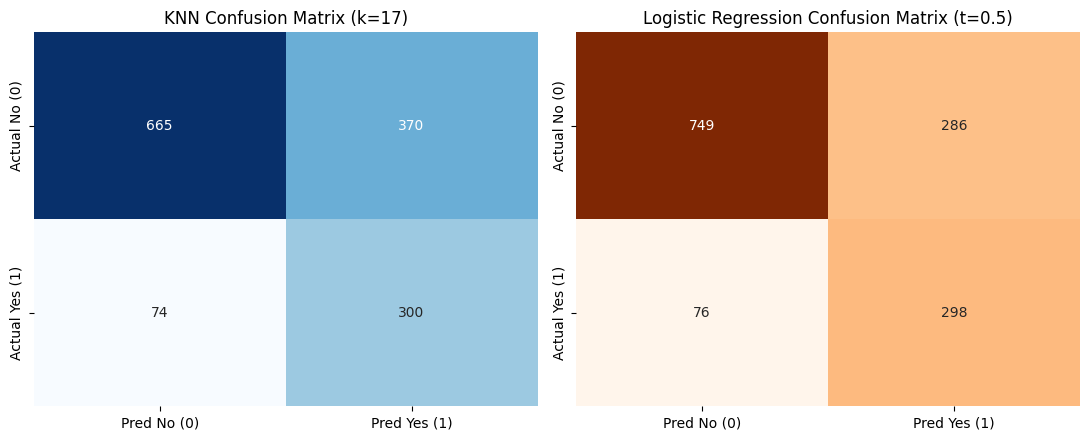

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred No (0)", "Pred Yes (1)"],
    yticklabels=["Actual No (0)", "Actual Yes (1)"],
    ax=axes[0],
)
axes[0].set_title(f"KNN Confusion Matrix (k={best_k})")

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Pred No (0)", "Pred Yes (1)"],
    yticklabels=["Actual No (0)", "Actual Yes (1)"],
    ax=axes[1],
)
axes[1].set_title("Logistic Regression Confusion Matrix (t=0.5)")

plt.tight_layout()
plt.show()